# Irish day-ahead prices and what drives them

A first look at one year of the data collected by `isem-data`: SEMO day-ahead prices next to EirGrid wind and demand, from November 2025 to November 2026.

The questions:

1. Is the data complete?
2. How did prices move over the year?
3. What does a typical day look like?
4. How often are prices extreme (negative, zero, spikes)?
5. How much does wind move the price?
6. Is wind or *net demand* (demand minus wind) the better single driver?
7. Why did prices rise so much over the year?
8. How good is EirGrid's wind forecast?

The last section turns the answers into a plan for forecasting.

Run `python -m isem_data --start 2025-11-07` first so `data/` has the full year.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from isem_data import storage

# One colour per series, always in this order (a colour-blind-safe palette).
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#e6e5e1", "#fcfcfb"

plt.rcParams.update(
    {
        "figure.figsize": (10, 4),
        "figure.dpi": 90,
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.edgecolor": MUTED,
        "axes.labelcolor": MUTED,
        "axes.grid": True,
        "axes.axisbelow": True,
        "axes.titlesize": 12,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "grid.color": GRID,
        "grid.linewidth": 0.8,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "text.color": INK,
        "lines.linewidth": 1.5,
        "legend.frameon": False,
    }
)
pd.set_option("display.precision", 1)

## The data, as one half-hourly table

Prices are half-hourly; EirGrid's wind and demand are every 15 minutes. Averaging each pair of 15-minute readings gives one value per half-hour, so everything lines up on the same timestamps.

ROI and NI prices are the same in all but four half-hours of the year (by one cent), so ROI stands in for the island.

In [2]:
prices = storage.load("prices")
wind = storage.load("wind")
demand = storage.load("demand")

price = prices.query("region == 'ROI' and series == 'dam_price_eur_mwh'")
price = price.set_index("timestamp_utc")["value"].rename("price")

grid = pd.concat([wind, demand]).pivot_table(
    index="timestamp_utc", columns="series", values="value"
)
grid = grid.resample("30min").mean()  # two 15-minute readings -> one half-hour

df = grid.join(price, how="inner").dropna()
df["net_demand_mw"] = df["demand_actual_mw"] - df["wind_actual_mw"]
df["wind_share"] = df["wind_actual_mw"] / df["demand_actual_mw"]

local = df.index.tz_convert("Europe/Dublin")  # for "time of day", Irish clock time matters
df["hour"] = local.hour
df["month"] = local.strftime("%Y-%m")

df.head()

,demand_actual_mw,wind_actual_mw,wind_forecast_mw,price,net_demand_mw,wind_share,hour,month
timestamp_utc,,,,,,,,
2025-11-07 00:00:00+00:00,4255.5,1712.0,1136.5,93.2,2543.5,0.4,0,2025-11
2025-11-07 00:30:00+00:00,4132.0,1695.5,1146.0,91.2,2436.5,0.4,0,2025-11
2025-11-07 01:00:00+00:00,4059.0,1667.0,1165.5,88.2,2392.0,0.4,1,2025-11
2025-11-07 01:30:00+00:00,3975.5,1658.5,1216.5,87.2,2317.0,0.4,1,2025-11
2025-11-07 02:00:00+00:00,3991.0,1751.0,1276.0,86.0,2240.0,0.4,2,2025-11


## 1. Is the data complete?

In [3]:
expected = pd.date_range(df.index.min(), df.index.max(), freq="30min")
missing = expected.difference(df.index)

print(f"{df.index.min():%d %b %Y %H:%M} to {df.index.max():%d %b %Y %H:%M} UTC")
print(f"{len(df):,} half-hours with price, wind and demand; {len(missing)} missing")
print(missing)

07 Nov 2025 00:00 to 04 Nov 2026 22:30 UTC
17,418 half-hours with price, wind and demand; 4 missing
DatetimeIndex(['2026-10-25 00:00:00+00:00', '2026-10-25 00:30:00+00:00',
               '2026-10-25 01:00:00+00:00', '2026-10-25 01:30:00+00:00'],
              dtype='datetime64[us, UTC]', freq='30min')


## 2. Prices over the year

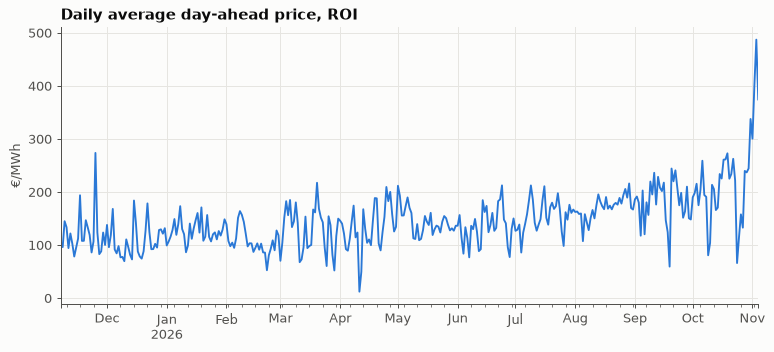

month,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09,2026-10,2026-11
average €/MWh,120.0,108.0,127.0,108.0,129.0,131.0,145.0,136.0,156.0,171.0,182.0,203.0,391.0


In [4]:
daily = df["price"].resample("D").mean()

ax = daily.plot(color=BLUE)
ax.set_title("Daily average day-ahead price, ROI")
ax.set_ylabel("€/MWh")
ax.set_xlabel("")
plt.show()

monthly = df.groupby("month")["price"].mean().round(0)
monthly.to_frame("average €/MWh").T

## 3. What does a typical day look like?

Average price for each hour of the day (Irish time), in winter (November to February) and summer (May to August).

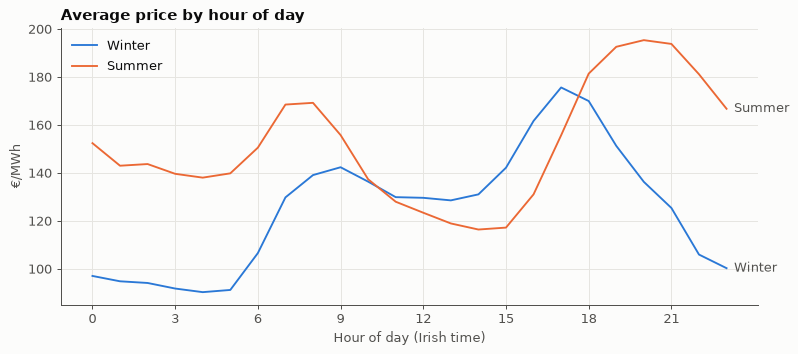

Cheapest hour on average: 4:00 (€121); dearest: 18:00 (€189)


In [5]:
winter = df[local.month.isin([11, 12, 1, 2])]
summer = df[local.month.isin([5, 6, 7, 8])]

fig, ax = plt.subplots()
for season, rows, colour in [("Winter", winter, BLUE), ("Summer", summer, ORANGE)]:
    profile = rows.groupby("hour")["price"].mean()
    ax.plot(profile.index, profile.values, color=colour, label=season)
    ax.annotate(
        season,
        (23, profile.iloc[-1]),
        xytext=(6, 0),
        textcoords="offset points",
        color=MUTED,
        va="center",
    )
ax.set_title("Average price by hour of day")
ax.set_xlabel("Hour of day (Irish time)")
ax.set_ylabel("€/MWh")
ax.set_xticks(range(0, 24, 3))
ax.legend(loc="upper left")
plt.show()

hourly = df.groupby("hour")["price"].mean()
print(
    f"Cheapest hour on average: {hourly.idxmin()}:00 (€{hourly.min():.0f}); "
    f"dearest: {hourly.idxmax()}:00 (€{hourly.max():.0f})"
)

## 4. How often are prices extreme?

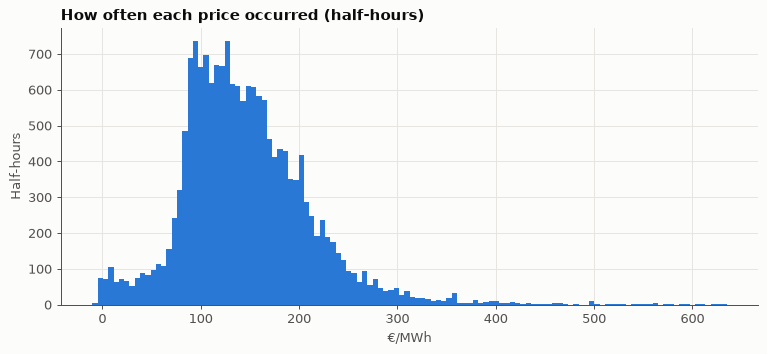

count    17418.0
mean       146.3
std         66.6
min        -10.1
1%           8.0
25%        102.6
50%        137.5
75%        180.9
99%        359.7
max        634.7

Negative: 8 half-hours; exactly zero: 58

Five highest half-hours:


,price,demand_actual_mw,wind_actual_mw
timestamp_utc,,,
2026-11-03 08:30:00+00:00,634.7,6098.5,444.5
2026-11-03 16:30:00+00:00,625.8,6490.5,496.5
2026-11-03 08:00:00+00:00,624.3,6066.0,428.5
2026-11-03 09:00:00+00:00,620.9,6171.0,450.5
2026-11-03 07:30:00+00:00,613.0,5911.0,432.0


In [6]:
fig, ax = plt.subplots()
ax.hist(df["price"], bins=120, color=BLUE)
ax.set_title("How often each price occurred (half-hours)")
ax.set_xlabel("€/MWh")
ax.set_ylabel("Half-hours")
plt.show()

print(df["price"].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).round(1).to_string())
print(f"\nNegative: {(df['price'] < 0).sum()} half-hours; exactly zero: {(df['price'] == 0).sum()}")
print("\nFive highest half-hours:")
df.nlargest(5, "price")[["price", "demand_actual_mw", "wind_actual_mw"]]

## 5. How much does wind move the price?

Each dot is a half-hour. The orange line is the median price for each band of wind share (wind output as a share of demand).

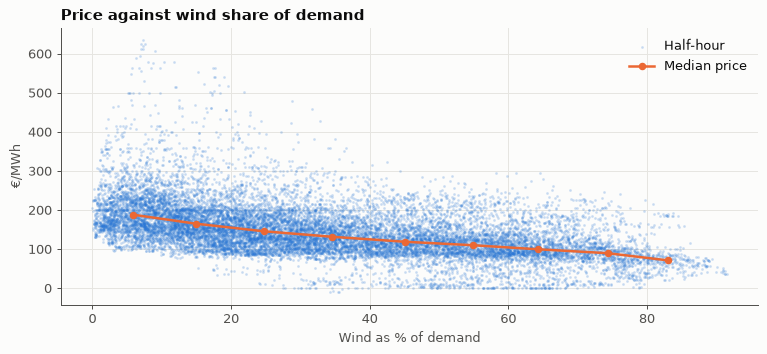

,median €/MWh,half-hours
wind_share,,
"(0.0, 0.1]",188.0,2625
"(0.1, 0.2]",165.0,3086
"(0.2, 0.3]",145.6,2810
"(0.3, 0.4]",131.6,2291
"(0.4, 0.5]",118.9,1976
"(0.5, 0.6]",110.0,1892
"(0.6, 0.7]",99.6,1545
"(0.7, 0.8]",89.5,901
"(0.8, 2.0]",71.0,291


In [7]:
bands = pd.cut(df["wind_share"], bins=[0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 2])
by_band = df.groupby(bands, observed=True)["price"].agg(["median", "size"])
centres = df.groupby(bands, observed=True)["wind_share"].median()

fig, ax = plt.subplots()
ax.scatter(df["wind_share"] * 100, df["price"], s=2, alpha=0.15, color=BLUE, label="Half-hour")
ax.plot(
    centres * 100,
    by_band["median"],
    color=ORANGE,
    linewidth=2,
    marker="o",
    markersize=5,
    label="Median price",
)
ax.set_title("Price against wind share of demand")
ax.set_xlabel("Wind as % of demand")
ax.set_ylabel("€/MWh")
ax.legend(loc="upper right")
plt.show()

by_band.rename(columns={"median": "median €/MWh", "size": "half-hours"})

## 6. Wind or net demand?

*Net demand* is what's left for other power stations (mostly gas) once wind is used: demand minus wind. If gas plants set the price, net demand should explain it better than wind alone.

In [8]:
drivers = ["wind_actual_mw", "wind_share", "demand_actual_mw", "net_demand_mw"]
df[drivers + ["price"]].corr()["price"].drop("price").round(2).to_frame("correlation with price")

,correlation with price
wind_actual_mw,-0.5
wind_share,-0.5
demand_actual_mw,0.2
net_demand_mw,0.6


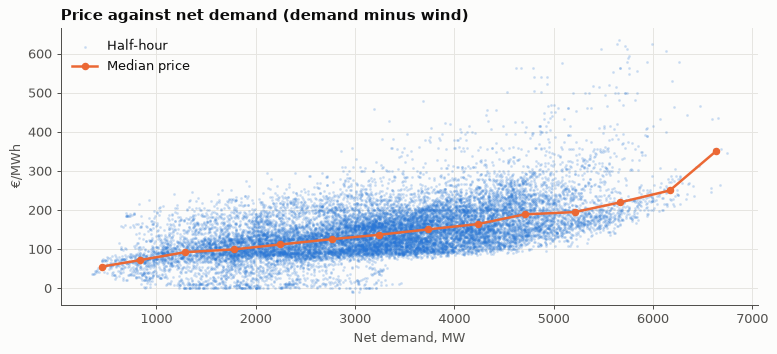

In [9]:
bands = pd.cut(df["net_demand_mw"], bins=range(-2000, 7001, 500))
by_band = df.groupby(bands, observed=True)["price"].median()
centres = df.groupby(bands, observed=True)["net_demand_mw"].median()

fig, ax = plt.subplots()
ax.scatter(df["net_demand_mw"], df["price"], s=2, alpha=0.15, color=BLUE, label="Half-hour")
ax.plot(centres, by_band, color=ORANGE, linewidth=2, marker="o", markersize=5, label="Median price")
ax.set_title("Price against net demand (demand minus wind)")
ax.set_xlabel("Net demand, MW")
ax.set_ylabel("€/MWh")
ax.legend(loc="upper left")
plt.show()

## 7. Why did prices rise over the year?

If prices rose because more had to come from gas (less wind, more demand), net demand should have risen too. If net demand stayed flat while prices rose, the cause lies outside this data, most likely the price of gas or carbon.

In [10]:
by_month = df.groupby("month").agg(
    price=("price", "mean"),
    demand_mw=("demand_actual_mw", "mean"),
    wind_mw=("wind_actual_mw", "mean"),
    net_demand_mw=("net_demand_mw", "mean"),
)
by_month.round(0)

,price,demand_mw,wind_mw,net_demand_mw
month,,,,
2025-11,120.0,5240.0,1876.0,3364.0
2025-12,108.0,5221.0,2048.0,3173.0
2026-01,127.0,5495.0,1883.0,3612.0
2026-02,108.0,5399.0,2278.0,3121.0
2026-03,129.0,5080.0,2069.0,3012.0
2026-04,131.0,4760.0,1804.0,2956.0
2026-05,145.0,4514.0,1290.0,3223.0
2026-06,136.0,4464.0,1369.0,3095.0
2026-07,156.0,4413.0,1026.0,3387.0


In [11]:
# The same comparison at a fixed net demand: the median price when 3,500-4,500 MW
# has to come from non-wind plants, month by month.
middle = df[df["net_demand_mw"].between(3500, 4500)]
label = "median €/MWh at 3.5-4.5 GW net demand"
middle.groupby("month")["price"].median().round(0).to_frame(label).T

month,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09,2026-10,2026-11
median €/MWh at 3.5-4.5 GW net demand,112.0,106.0,115.0,109.0,151.0,170.0,159.0,158.0,180.0,167.0,222.0,233.0,368.0


## 8. How good is EirGrid's wind forecast?

The forecast stored here is EirGrid's *latest* version, which may have been revised after the day-ahead auction closed. So this flatters the forecast a trader actually had.

In [12]:
error = df["wind_forecast_mw"] - df["wind_actual_mw"]
mae = error.abs().mean()
share = mae / df["wind_actual_mw"].mean()
print(f"Mean absolute error: {mae:.0f} MW, {share:.0%} of average wind output")
print(f"Average error (bias): {error.mean():+.0f} MW (positive = forecast too high)")

Mean absolute error: 373 MW, 22% of average wind output
Average error (bias): +300 MW (positive = forecast too high)


## Takeaways

**The data is complete.** 17,418 half-hours have a price, wind and demand. The only 4 missing are the repeated hour when the clocks went back on 25 October.

**Prices.** The median half-hour was €137.5/MWh. 98% of half-hours fell between €8 and €360. There were 8 negative and 58 zero half-hours. Monthly averages sat at €108–131 from November to April, then climbed to €203 in October. The first days of November 2026 averaged €391: all five dearest half-hours of the year fell on 3 November, with demand around 6 GW and wind under 500 MW.

**A typical day** has a morning peak around 08:00–09:00 and a higher evening peak. On average the cheapest hour is 04:00 (€121) and the dearest 18:00 (€189). In summer the evening peak comes later, around 20:00. Summer prices look higher at most hours partly because prices rose through the year and summer came later, so compare the *shapes*, not the levels.

**Wind pushes prices down, steadily.** The median price falls from €188 when wind covers under 10% of demand to €71 when it covers over 80%.

**Net demand is the best single driver.** Its correlation with price is 0.6, against −0.5 for wind and 0.2 for demand alone: what matters is how much is left for gas plants once wind is used.

**But wind and demand don't explain the rise over the year.** Average net demand stayed between about 3.0 and 3.7 GW in every full month. At the *same* net demand (3.5–4.5 GW), the median price climbed from €106–115 in winter to €222–233 in September and October. The cause is outside this data. Gas and carbon prices are the obvious suspects, since gas plants usually set the price, but this notebook can't confirm that.

**EirGrid's wind forecast is off by 373 MW on average** (22% of average output), and it is **too high by 300 MW on average**. A bias that large suggests the forecast and the "actual" measure different things. One likely reason is that the actual figure is after wind farms were turned down for grid reasons (dispatch-down), but that needs checking.

## What this means for forecasting

- **What to forecast:** tomorrow's 48 half-hourly day-ahead prices, as they would be known before the auction at 11:00 UTC the day before.
- **Only use what was known before the auction:** EirGrid's wind forecast, a demand forecast, the calendar (hour, weekday, holidays), and recent prices. Actual wind and demand come too late.
- **Baselines to beat first:** "the same half-hour yesterday" and "the same half-hour last week". A model is only worth having if it beats these.
- **Most promising inputs:** forecast net demand (forecast demand minus forecast wind), hour of day and day of week, and the recent price level, which partly stands in for gas prices.
- **Gaps to close before modelling:**
  1. a demand forecast (the `demandforecast` area returned nothing from EirGrid's API, so another source or area name is needed);
  2. forecasts as they stood at auction time, not later revisions (`keep="last"` overwrites revisions);
  3. a gas price series, to explain level shifts like this year's rise.
- **Test fairly:** train on earlier months and test on later ones, never a random split, and retrain as time moves on ("walk-forward"). The level shift this year means a model trained on winter prices would badly under-predict the autumn.
